In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# تنظیمات نمایش
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style="whitegrid")

print("کتابخانه‌ها با موفقیت لود شدند!")

کتابخانه‌ها با موفقیت لود شدند!


In [2]:
# آدرس فایل دیتا (چون توی پوشه notebooks هستیم، باید یک پوشه عقب بریم)
data_path = "../data/raw/Telco-Customer-Churn.csv"

# لود کردن داده‌ها
df = pd.read_csv(data_path)

# نمایش ۵ ردیف اول
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# ۱. ابعاد داده (تعداد ردیف و ستون)
print("Shape of data:", df.shape)
print("-"  30)

# ۲. اطلاعات کلی ستون‌ها و نوع داده‌ها
df.info()
print("-"  30)

# ۳. بررسی داده‌های گمشده (Missing Values)
print("Missing values per column:")
print(df.isnull().sum())

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1955694837.py, line 3)

In [4]:
# ۱. ابعاد داده (تعداد ردیف و ستون)
print("Shape of data:", df.shape)
print("-"  30)

# ۲. اطلاعات کلی ستون‌ها و نوع داده‌ها
df.info()
print("-" * 30)

# ۳. بررسی داده‌های گمشده (Missing Values)
print("Missing values per column:")
print(df.isnull().sum())

SyntaxError: invalid syntax. Perhaps you forgot a comma? (2334396603.py, line 3)

In [5]:
# ۱. ابعاد داده (تعداد ردیف و ستون)
print("Shape of data:", df.shape)
print("-" * 30)

# ۲. اطلاعات کلی ستون‌ها و نوع داده‌ها
df.info()
print("-" * 30)

# ۳. بررسی داده‌های گمشده (Missing Values)
print("Missing values per column:")
print(df.isnull().sum())

Shape of data: (7043, 21)
------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 

In [6]:
# ۱. تبدیل ستون TotalCharges به نوع عددی (مقادیر غیر عددی تبدیل به NaN میشن)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# ۲. حالا ببینیم چند تا NaN ساختیم
print("Missing values in TotalCharges:", df['TotalCharges'].isnull().sum())

# ۳. حذف ردیف‌هایی که TotalCharges اونها NaN شده
df = df.dropna(subset=['TotalCharges'])

# ۴. چک کردن ابعاد جدید داده (چند ردیف کم شد؟)
print("New shape:", df.shape)

Missing values in TotalCharges: 11
New shape: (7032, 21)


درصد مشتریان:
 Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


C:\Users\T3mplaR\AppData\Local\Temp\ipykernel_12636\1267594398.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2')


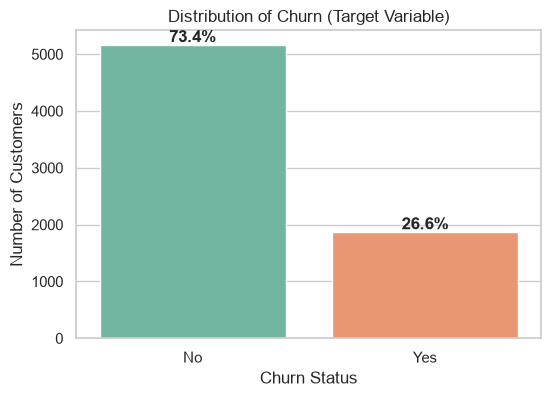

In [7]:
# ۱. محاسبه درصدها
churn_counts = df['Churn'].value_counts(normalize=True) * 100
print("درصد مشتریان:\n", churn_counts)

# ۲. رسم نمودار میله‌ای
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Distribution of Churn (Target Variable)')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

# اضافه کردن درصدها روی میله‌ها
for i, count in enumerate(df['Churn'].value_counts()):
    plt.text(i, count + 50, f"{churn_counts.iloc[i]:.1f}%", ha='center', fontweight='bold')

plt.show()

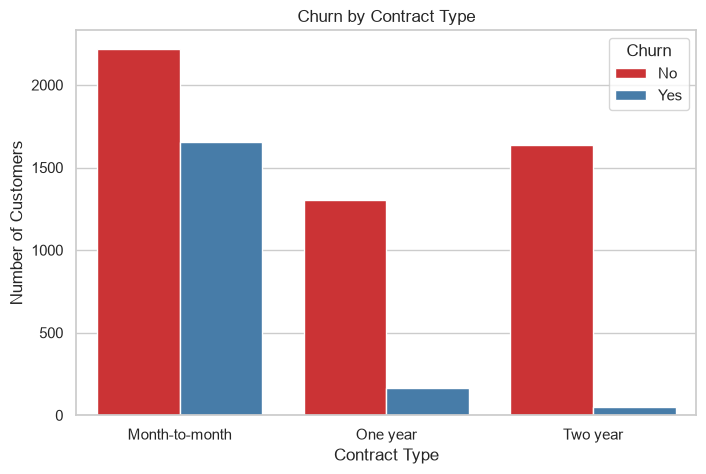

In [8]:
# رسم نمودار Contract در برابر Churn
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1')

plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')
plt.show()

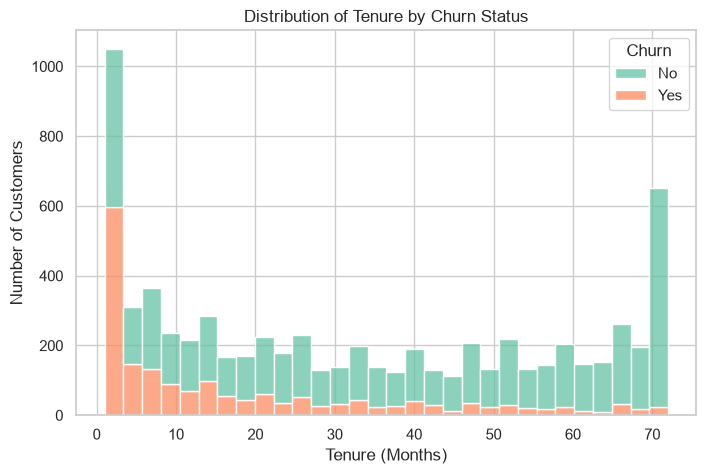

In [9]:
plt.figure(figsize=(8, 5))

# رسم توزیع tenure بر اساس وضعیت Churn
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=30, palette='Set2')

plt.title('Distribution of Tenure by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

## خلاصه بینش‌های کلیدی (EDA Insights)

1. *عدم تعادل داده (Imbalanced Data): حدود ۷۳.۴٪ از مشتری‌ها می‌مونن و ۲۶.۶٪ ریزش می‌کنن. برای آموزش مدل باید به این عدم تعادل توجه کنیم.
2. نوع قرارداد (Contract): مشتری‌های ماه‌به‌ماه (Month-to-month) بیشترین ریزش را دارند، در حالی که قراردادهای دوساله تقریباً هیچ ریزشی ندارند.
3. مدت زمان حضور (Tenure): مشتریان جدید (ماه‌های اولیه) بالاترین نرخ ریزش را دارند و مشتریان با سابقه بالای ۷۰ ماه، بسیار وفادار هستند.
4. داده‌های گمشده:* ۱۱ رکورد در ستون TotalCharges مشکل داشتند که به‌درستی حذف شدند.

In [10]:
# ۱. حذف ستون customerID چون شناسه است و برای مدل هیچ ارزشی ندارد
df_model = df.drop('customerID', axis=1)

# ۲. تبدیل ستون Churn (متغیر هدف) به عدد 0 و 1
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

# ۳. تبدیل بقیه ستون‌های متنی به اعداد (One-Hot Encoding)
# drop_first=True باعث میشه ستون‌های تکراری حذف بشن و دیتا سبک‌تر بشه
df_model = pd.get_dummies(df_model, drop_first=True)

# ۴. نمایش ۵ ردیف اول دیتای نهایی
df_model.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
